In [2]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
%config InlineBackend.figure_format='retina'
import sys; print(sys.version)
sys.path.append('python-src')
from import_all_notebook_hook import *

3.8.2 (default, Mar 26 2020, 15:53:00) 
[GCC 7.3.0]


In [3]:
YES_SIGNATURE_PATH = './dataset-firmas/signatures-2/PDF-2451-51-0-PAG-0-presidente.PNG'
NO_SIGNATURE_PATH = './dataset-firmas/signatures-2/PDF-2453-51-8-PAG-0-aux2.PNG'

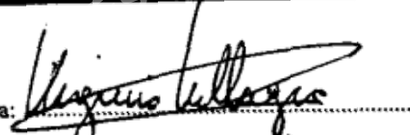

In [4]:
img = Image.open(YES_SIGNATURE_PATH)
img

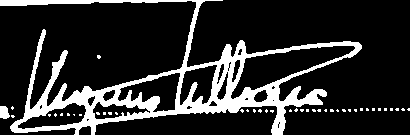

In [5]:
np_img = np.array(img)
_,np_img = cv2.threshold(cv2.GaussianBlur(np.array(img),(5,5),0),0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
np_img = 255-np_img
Image.fromarray(np_img)

<ipython-input-6-3f0d59ddf17e>:3: FutureWarning: The new recommended value for bg_label is 0. Until version 0.19, the default bg_label value is -1. From version 0.19, the bg_label default value will be 0. To avoid this warning, please explicitly set bg_label value.
  image_label_overlay = label2rgb(blobs_labels, image=np_img)


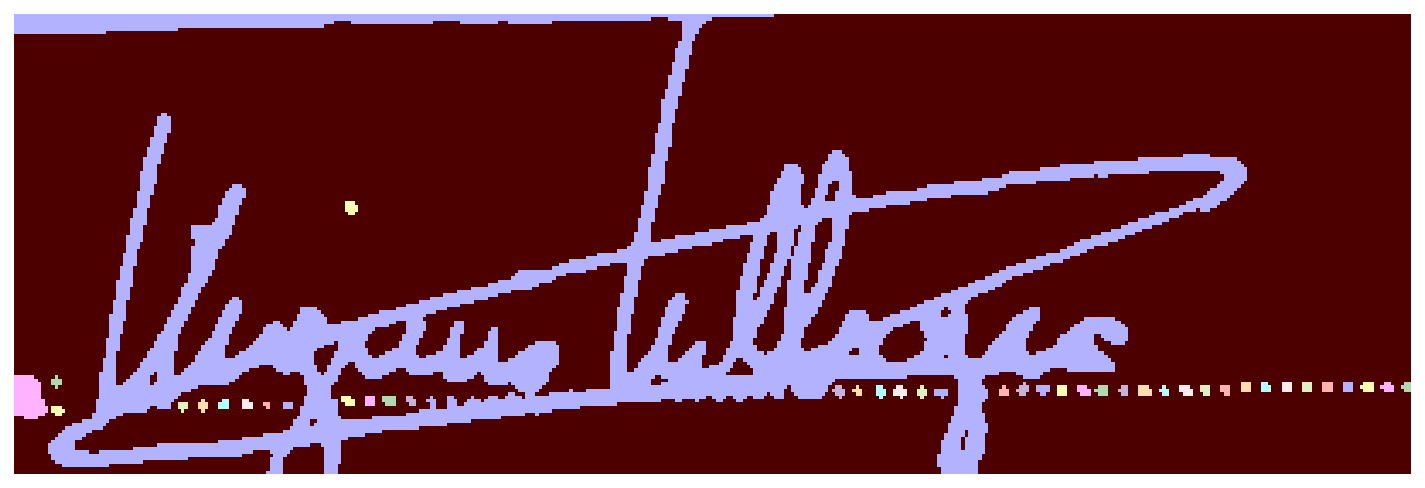

In [6]:
# connected component analysis by scikit-learn framework
blobs_labels = measure.label(np_img, background=0)
image_label_overlay = label2rgb(blobs_labels, image=np_img)

fig, ax = plt.subplots(figsize=(10, 6))
# plot the connected components (for debugging)
ax.imshow(image_label_overlay)
ax.set_axis_off()
plt.tight_layout()
plt.show()

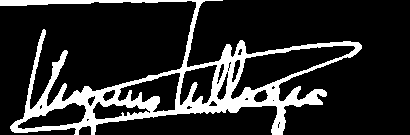

In [7]:
preserved_region = []
SOLIDITY_THRESOLD = 0.5
for region in regionprops(blobs_labels):
    #print(region.area, region.convex_area, region.solidity, region.perimeter, region.eccentricity, region.euler_number)
    if region.solidity<SOLIDITY_THRESOLD:
        #print(region.area, region.convex_area, region.solidity, region.perimeter)
        preserved_region.append(region.label)


filtered_labels = blobs_labels.copy()
filtered_labels[~np.isin(filtered_labels, preserved_region)] = 0


filtered_np_img = np_img.copy()
filtered_np_img[filtered_labels==0] = 0
Image.fromarray(filtered_np_img)